In [1]:
from pathlib import Path
import os
import sys
import json
import math
import hashlib
import shutil
import subprocess
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data_fame_gpu"
OUT_DIR = ROOT / "outputs_fame_gpu"
REPO_DIR = ROOT / "26ASPLOS-Spot"

DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("Diretório:", ROOT.resolve())

Python: 3.13.14
Diretório: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU


In [2]:
ALIBABA_BASE = "https://raw.githubusercontent.com/alibaba/clusterdata/master/cluster-trace-v2026-spot-gpu"
URL_JOB = f"{ALIBABA_BASE}/job_info_df.csv"
URL_NODE = f"{ALIBABA_BASE}/node_info_df.csv"

GFS_REPO = "https://github.com/MachineLearningSystem/26ASPLOS-Spot.git"

JOB_FILE = DATA_DIR / "job_info_df.csv"
NODE_FILE = DATA_DIR / "node_info_df.csv"

TRACE_ORIGIN = pd.Timestamp("2024-03-01 00:00:00")
TRACE_END_GFS = pd.Timestamp("2024-08-31 23:59:59")

EXPECTED_JOB_COLUMNS = {
    "job_name", "organization", "gpu_model", "cpu_request",
    "gpu_request", "worker_num", "submit_time", "duration", "job_type"
}
EXPECTED_NODE_COLUMNS = {
    "gpu_model", "gpu_capacity_num", "cpu_num", "node_name"
}

print(URL_JOB)
print(URL_NODE)

https://raw.githubusercontent.com/alibaba/clusterdata/master/cluster-trace-v2026-spot-gpu/job_info_df.csv
https://raw.githubusercontent.com/alibaba/clusterdata/master/cluster-trace-v2026-spot-gpu/node_info_df.csv


In [3]:
def download_stream(url: str, path: Path, overwrite: bool = False, chunk_mb: int = 4):
    
    if path.exists() and not overwrite:
        print(f"[OK] Já existe: {path} ({path.stat().st_size/1e6:.2f} MB)")
        return path

    tmp = path.with_suffix(path.suffix + ".part")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(tmp, "wb") as f:
        total = int(r.headers.get("Content-Length", 0))
        done = 0
        chunk = chunk_mb * 1024 * 1024
        while True:
            block = r.read(chunk)
            if not block:
                break
            f.write(block)
            done += len(block)
            if total:
                print(f"\r{path.name}: {100*done/total:5.1f}% ", end="")
    tmp.replace(path)
    print(f"\n[OK] {path} ({path.stat().st_size/1e6:.2f} MB)")
    return path

download_stream(URL_JOB, JOB_FILE)
download_stream(URL_NODE, NODE_FILE)

[OK] Já existe: c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\data_fame_gpu\job_info_df.csv (23.06 MB)
[OK] Já existe: c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\data_fame_gpu\node_info_df.csv (0.08 MB)


WindowsPath('c:/Users/tiago/Dropbox/Artigos/FAME/FAME/Artigo 2 - AOR/FAME_GPU/data_fame_gpu/node_info_df.csv')

In [4]:
def sha256(path: Path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

print("job_info_df.csv SHA256 :", sha256(JOB_FILE))
print("node_info_df.csv SHA256:", sha256(NODE_FILE))

job_info_df.csv SHA256 : 113ccee4c28f5c3bbaaca974cd164b9280b7d4c39e53b745443b28eea05e03dd
node_info_df.csv SHA256: 1aba161961a5a4a1a61aa581383c5e5abe3400b59f8597ba8c4eef7597bc9d18


In [5]:
jobs = pd.read_csv(JOB_FILE)
nodes = pd.read_csv(NODE_FILE)

print("jobs :", jobs.shape)
print("nodes:", nodes.shape)

missing_job_cols = EXPECTED_JOB_COLUMNS - set(jobs.columns)
missing_node_cols = EXPECTED_NODE_COLUMNS - set(nodes.columns)

assert not missing_job_cols, f"Colunas ausentes em jobs: {missing_job_cols}"
assert not missing_node_cols, f"Colunas ausentes em nodes: {missing_node_cols}"

display(jobs.head())
display(nodes.head())

jobs : (466867, 9)
nodes: (4278, 4)


,job_name,organization,gpu_model,cpu_request,gpu_request,worker_num,submit_time,duration,job_type
0,239255,13,A10,20.0,1.0,1,0.0,2764799.0,HP
1,253689,13,A10,8.0,1.0,1,0.0,15897599.0,HP
2,236907,13,A10,8.0,1.0,1,0.0,9857174.0,HP
3,253671,13,GPU-series-1,4.0,1.0,1,0.0,1727999.0,HP
4,236901,13,A10,8.0,1.0,1,0.0,15897599.0,HP


,gpu_model,gpu_capacity_num,cpu_num,node_name
0,GPU-series-1,4,192,0
1,GPU-series-1,1,192,1
2,A10,1,128,2
3,A100-SXM4-80GB,8,128,3
4,GPU-series-1,1,192,4


In [6]:
for c in ["cpu_request", "gpu_request", "worker_num", "submit_time", "duration"]:
    jobs[c] = pd.to_numeric(jobs[c], errors="coerce")

for c in ["gpu_capacity_num", "cpu_num"]:
    nodes[c] = pd.to_numeric(nodes[c], errors="coerce")

jobs["requested_gpus"] = jobs["gpu_request"] * jobs["worker_num"]
jobs["requested_cpu"] = jobs["cpu_request"] * jobs["worker_num"]
jobs["duration_hours"] = jobs["duration"] / 3600
jobs["requested_gpu_hours"] = jobs["requested_gpus"] * jobs["duration_hours"]

jobs["submit_day"] = jobs["submit_time"] / 86400
jobs["submit_hour"] = jobs["submit_time"] / 3600

jobs["timestamp_gfs"] = TRACE_ORIGIN + pd.to_timedelta(jobs["submit_time"], unit="s")
jobs["date_gfs"] = jobs["timestamp_gfs"].dt.floor("D")
jobs["hour_gfs"] = jobs["timestamp_gfs"].dt.floor("h")

display(jobs[[
    "job_name", "organization", "gpu_model", "job_type",
    "gpu_request", "worker_num", "requested_gpus",
    "submit_time", "timestamp_gfs", "duration_hours"
]].head())

,job_name,organization,gpu_model,job_type,gpu_request,worker_num,requested_gpus,submit_time,timestamp_gfs,duration_hours
0,239255,13,A10,HP,1.0,1,1.0,0.0,2024-03-01,767.999722
1,253689,13,A10,HP,1.0,1,1.0,0.0,2024-03-01,4415.999722
2,236907,13,A10,HP,1.0,1,1.0,0.0,2024-03-01,2738.103889
3,253671,13,GPU-series-1,HP,1.0,1,1.0,0.0,2024-03-01,479.999722
4,236901,13,A10,HP,1.0,1,1.0,0.0,2024-03-01,4415.999722


In [7]:
quality = pd.Series({
    "n_jobs": len(jobs),
    "n_nodes": len(nodes),
    "duplicate_job_name": jobs["job_name"].duplicated().sum(),
    "missing_total_jobs": int(jobs.isna().sum().sum()),
    "missing_total_nodes": int(nodes.isna().sum().sum()),
    "duration_le_0": int((jobs["duration"] <= 0).sum()),
    "gpu_request_le_0": int((jobs["gpu_request"] <= 0).sum()),
    "worker_num_le_0": int((jobs["worker_num"] <= 0).sum()),
    "submit_time_lt_0": int((jobs["submit_time"] < 0).sum()),
    "job_gpu_not_in_node_inventory": int((~jobs["gpu_model"].isin(nodes["gpu_model"].unique())).sum()),
})
display(quality.to_frame("value"))

print("\nMissing por coluna — jobs")
display(jobs.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nMissing por coluna — nodes")
display(nodes.isna().sum().sort_values(ascending=False).to_frame("missing"))

,value
n_jobs,466867
n_nodes,4278
duplicate_job_name,0
missing_total_jobs,0
missing_total_nodes,0
duration_le_0,0
gpu_request_le_0,0
worker_num_le_0,0
submit_time_lt_0,0
job_gpu_not_in_node_inventory,0



Missing por coluna — jobs


,missing
job_name,0
organization,0
gpu_model,0
cpu_request,0
gpu_request,0
worker_num,0
submit_time,0
duration,0
job_type,0
requested_gpus,0



Missing por coluna — nodes


,missing
gpu_model,0
gpu_capacity_num,0
cpu_num,0
node_name,0


In [8]:
temporal = {
    "min_submit_time_sec": float(jobs["submit_time"].min()),
    "max_submit_time_sec": float(jobs["submit_time"].max()),
    "trace_span_days": float((jobs["submit_time"].max() - jobs["submit_time"].min()) / 86400),
    "first_timestamp_gfs": str(jobs["timestamp_gfs"].min()),
    "last_timestamp_gfs": str(jobs["timestamp_gfs"].max()),
    "jobs_after_gfs_end": int((jobs["timestamp_gfs"] > TRACE_END_GFS).sum()),
}
display(pd.Series(temporal).to_frame("value"))

,value
min_submit_time_sec,0.0
max_submit_time_sec,15902470.0
trace_span_days,184.056366
first_timestamp_gfs,2024-03-01 00:00:00
last_timestamp_gfs,2024-09-01 01:21:10
jobs_after_gfs_end,23


In [9]:
node_summary = (
    nodes.groupby("gpu_model", dropna=False)
    .agg(
        nodes=("node_name", "count"),
        total_gpus=("gpu_capacity_num", "sum"),
        mean_gpus_per_node=("gpu_capacity_num", "mean"),
        total_cpu=("cpu_num", "sum"),
        mean_cpu_per_node=("cpu_num", "mean"),
    )
    .sort_values("total_gpus", ascending=False)
)

display(node_summary)
node_summary.to_csv(OUT_DIR / "gpu_inventory.csv")

,nodes,total_gpus,mean_gpus_per_node,total_cpu,mean_cpu_per_node
gpu_model,,,,,
A100-SXM4-80GB,432,3456,8.000000,55296,128.000000
A10,2494,2494,1.000000,319228,127.998396
H800,219,1752,8.000000,42048,192.000000
GPU-series-1,989,1558,1.575329,189824,191.935288
GPU-series-2,122,976,8.000000,23424,192.000000
A800-SXM4-80GB,22,176,8.000000,2816,128.000000


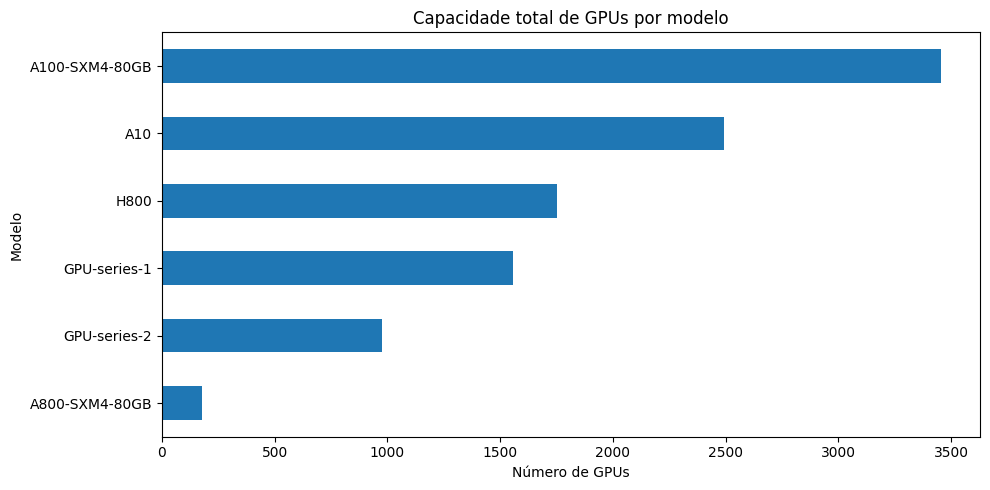

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
node_summary["total_gpus"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Capacidade total de GPUs por modelo")
ax.set_xlabel("Número de GPUs")
ax.set_ylabel("Modelo")
plt.tight_layout()
plt.show()

In [11]:
job_type_summary = (
    jobs.groupby("job_type")
    .agg(
        jobs=("job_name", "count"),
        requested_gpus=("requested_gpus", "sum"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
        median_duration_h=("duration_hours", "median"),
        mean_duration_h=("duration_hours", "mean"),
        p95_duration_h=("duration_hours", lambda x: x.quantile(.95)),
        organizations=("organization", "nunique"),
        gpu_models=("gpu_model", "nunique"),
    )
)
job_type_summary["job_share"] = job_type_summary["jobs"] / len(jobs)
display(job_type_summary)
job_type_summary.to_csv(OUT_DIR / "job_type_summary.csv")

,jobs,requested_gpus,requested_gpu_hours,median_duration_h,mean_duration_h,p95_duration_h,organizations,gpu_models,job_share
job_type,,,,,,,,,
HP,415713,2023331.94,3.857243e+07,0.305833,57.366950,175.542444,77,6,0.890431
Spot,51154,274635.00,9.592682e+05,0.582083,3.799884,9.962222,14,6,0.109569


In [12]:
gpu_workload = (
    jobs.groupby(["gpu_model", "job_type"])
    .agg(
        jobs=("job_name", "count"),
        requested_gpus=("requested_gpus", "sum"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
        organizations=("organization", "nunique"),
        median_duration_h=("duration_hours", "median"),
    )
    .reset_index()
)

display(gpu_workload.sort_values(["gpu_model", "job_type"]))
gpu_workload.to_csv(OUT_DIR / "gpu_workload_summary.csv", index=False)

,gpu_model,job_type,jobs,requested_gpus,requested_gpu_hours,organizations,median_duration_h
0,A10,HP,226881,197826.44,1.458597e+07,51,0.114167
1,A10,Spot,1762,12499.00,8.624803e+04,4,1.331250
2,A100-SXM4-80GB,HP,137396,688319.00,1.094060e+07,35,0.523056
3,A100-SXM4-80GB,Spot,31624,140449.00,3.876736e+05,10,0.478889
4,A800-SXM4-80GB,HP,4690,39037.00,4.991256e+05,1,0.393056
5,A800-SXM4-80GB,Spot,4109,14924.00,2.701343e+04,3,0.387778
6,GPU-series-1,HP,16054,16427.50,5.083539e+06,13,1.099306
7,GPU-series-1,Spot,2857,24416.00,1.334920e+05,2,2.605278
8,GPU-series-2,HP,22340,380222.00,2.648459e+06,8,0.372917
9,GPU-series-2,Spot,8057,62349.00,2.289769e+05,6,1.421944


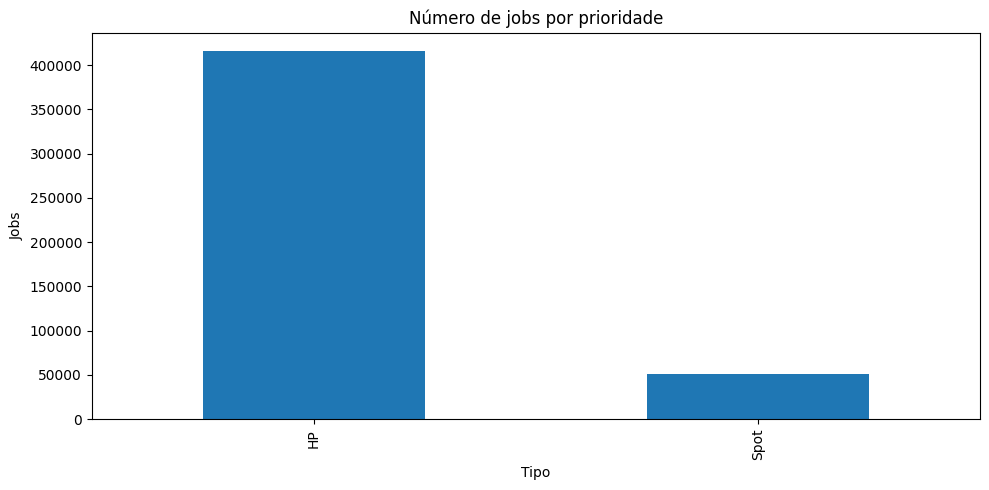

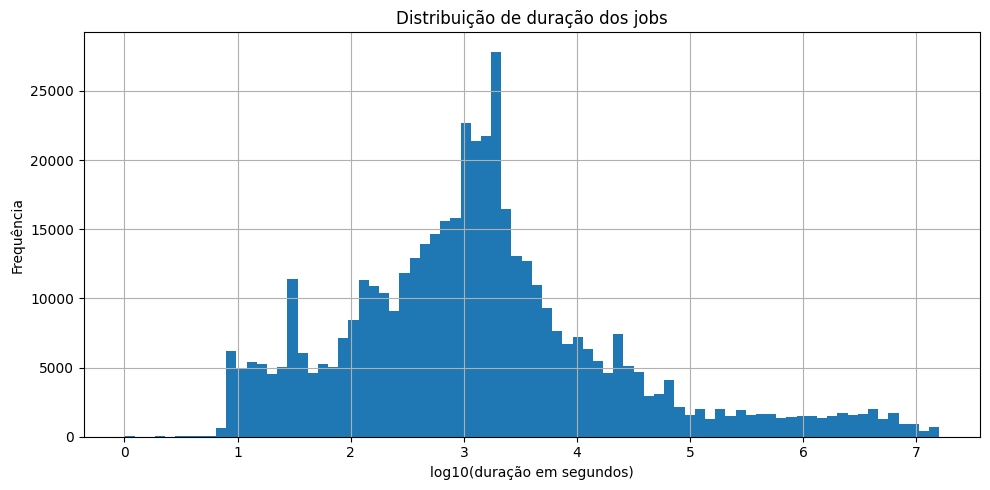

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
counts = jobs["job_type"].value_counts()
counts.plot(kind="bar", ax=ax)
ax.set_title("Número de jobs por prioridade")
ax.set_xlabel("Tipo")
ax.set_ylabel("Jobs")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
np.log10(jobs.loc[jobs["duration"] > 0, "duration"]).hist(bins=80, ax=ax)
ax.set_title("Distribuição de duração dos jobs")
ax.set_xlabel("log10(duração em segundos)")
ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

In [14]:
org_summary = (
    jobs.groupby("organization")
    .agg(
        jobs=("job_name", "count"),
        hp_jobs=("job_type", lambda x: (x == "HP").sum()),
        spot_jobs=("job_type", lambda x: (x == "Spot").sum()),
        gpu_models=("gpu_model", "nunique"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
        first_day=("submit_day", "min"),
        last_day=("submit_day", "max"),
    )
)
org_summary["has_both_classes"] = (org_summary["hp_jobs"] > 0) & (org_summary["spot_jobs"] > 0)
org_summary["active_span_days"] = org_summary["last_day"] - org_summary["first_day"]

print("Organizations:", len(org_summary))
print("Organizations com HP e Spot:", int(org_summary["has_both_classes"].sum()))
display(org_summary.sort_values("requested_gpu_hours", ascending=False).head(20))
org_summary.to_csv(OUT_DIR / "organization_summary.csv")

Organizations: 84
Organizations com HP e Spot: 7


,jobs,hp_jobs,spot_jobs,gpu_models,requested_gpu_hours,first_day,last_day,has_both_classes,active_span_days
organization,,,,,,,,,
13,181107,181107,0,5,1.271139e+07,0.000000,184.053519,False,184.053519
57,108911,70342,38569,6,1.137187e+07,0.000000,184.039387,True,184.039387
19,43293,43293,0,5,3.987630e+06,11.647141,183.946296,False,172.299155
66,45879,43452,2427,1,2.105088e+06,0.000000,184.056366,True,184.056366
4,13718,12654,1064,4,1.637783e+06,0.000000,183.376748,True,183.376748
67,13153,10661,2492,1,1.008737e+06,89.811076,184.044560,True,94.233484
18,11417,11417,0,4,1.002370e+06,91.706586,184.048021,False,92.341435
37,968,968,0,2,9.521568e+05,0.000000,182.620856,False,182.620856
24,16584,14159,2425,4,4.947359e+05,0.000000,184.049387,True,184.049387


In [15]:
hourly = (
    jobs.groupby(["hour_gfs", "job_type"])
    .agg(
        arrivals=("job_name", "count"),
        requested_gpus=("requested_gpus", "sum"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
    )
    .reset_index()
)

hourly_pivot = hourly.pivot(index="hour_gfs", columns="job_type", values="requested_gpus").fillna(0)
display(hourly_pivot.head())
hourly.to_csv(OUT_DIR / "hourly_workload.csv", index=False)

job_type,HP,Spot
hour_gfs,,
2024-03-01 00:00:00,6855.64,0.0
2024-03-01 01:00:00,292.00,8.0
2024-03-01 02:00:00,60.00,0.0
2024-03-01 03:00:00,96.00,0.0
2024-03-01 04:00:00,226.00,0.0


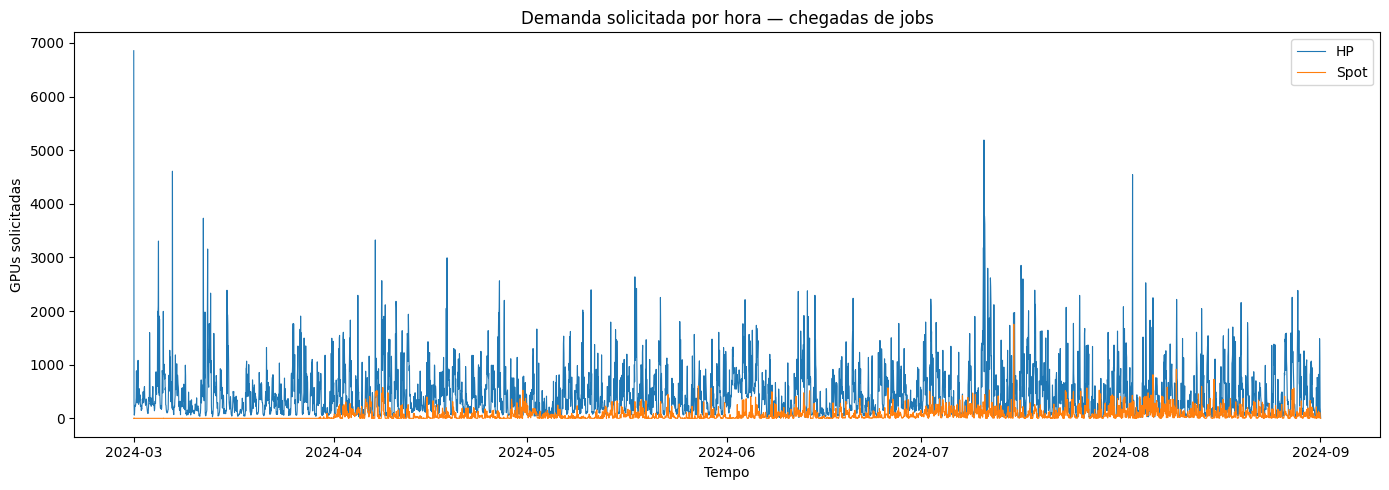

In [16]:
fig, ax = plt.subplots(figsize=(14, 5))
for col in hourly_pivot.columns:
    ax.plot(hourly_pivot.index, hourly_pivot[col], label=str(col), linewidth=0.8)
ax.set_title("Demanda solicitada por hora — chegadas de jobs")
ax.set_xlabel("Tempo")
ax.set_ylabel("GPUs solicitadas")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
hp_hourly_gpu = (
    jobs[jobs["job_type"] == "HP"]
    .groupby(["hour_gfs", "gpu_model"])["requested_gpus"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

full_hours = pd.date_range(
    jobs["hour_gfs"].min(),
    jobs["hour_gfs"].max(),
    freq="h"
)
hp_hourly_gpu = hp_hourly_gpu.reindex(full_hours, fill_value=0)

display(hp_hourly_gpu.describe().T)

,count,mean,std,min,25%,50%,75%,max
gpu_model,,,,,,,,
A10,4418.0,44.777374,77.513111,0.0,8.0,27.7,56.5,2249.14
A100-SXM4-80GB,4418.0,155.798778,179.394512,2.0,42.0,93.0,207.0,2252.00
A800-SXM4-80GB,4418.0,8.835899,19.923217,0.0,0.0,0.0,8.0,211.00
GPU-series-1,4418.0,3.718311,12.742879,0.0,1.0,2.0,4.0,738.00
GPU-series-2,4418.0,86.062019,138.787002,0.0,0.0,21.5,112.0,1064.00
H800,4418.0,158.782254,345.908366,0.0,0.0,0.0,136.0,4608.00


In [18]:
def burstiness_stats(x: pd.Series):
    x = pd.Series(x, dtype=float)
    mean = x.mean()
    median = x.median()
    std = x.std()
    return pd.Series({
        "mean": mean,
        "median": median,
        "std": std,
        "cv": std / mean if mean > 0 else np.nan,
        "p95": x.quantile(.95),
        "p99": x.quantile(.99),
        "peak": x.max(),
        "peak_to_mean": x.max() / mean if mean > 0 else np.nan,
        "p95_to_median": x.quantile(.95) / median if median > 0 else np.nan,
        "zero_hour_share": (x == 0).mean(),
    })

burst_gpu = hp_hourly_gpu.apply(burstiness_stats).T
display(burst_gpu.sort_values("cv", ascending=False))
burst_gpu.to_csv(OUT_DIR / "hp_burstiness_by_gpu.csv")

,mean,median,std,cv,p95,p99,peak,peak_to_mean,p95_to_median,zero_hour_share
gpu_model,,,,,,,,,,
GPU-series-1,3.718311,2.0,12.742879,3.427061,12.000,30.00,738.00,198.477188,6.000000,0.216840
A800-SXM4-80GB,8.835899,0.0,19.923217,2.254804,48.000,100.83,211.00,23.879858,NaN,0.593481
H800,158.782254,0.0,345.908366,2.178508,856.000,1533.28,4608.00,29.020875,NaN,0.513807
A10,44.777374,27.7,77.513111,1.731078,110.875,436.70,2249.14,50.229386,4.002708,0.028067
GPU-series-2,86.062019,21.5,138.787002,1.612639,375.150,622.81,1064.00,12.363177,17.448837,0.306021
A100-SXM4-80GB,155.798778,93.0,179.394512,1.151450,496.150,823.15,2252.00,14.454542,5.334946,0.000000


In [19]:
weekly_hp_gpu = hp_hourly_gpu.resample("7D").agg(["mean", "std", "max"])
display(weekly_hp_gpu.head())

gpu_model          A10                      A100-SXM4-80GB                     A800-SXM4-80GB                   GPU-series-1                   GPU-series-2  \
                  mean         std      max           mean         std     max           mean        std    max         mean        std    max         mean   
2024-03-01  154.767202  177.181105  2249.14     163.377976  219.997962  2116.5      19.910714  33.197076  168.0     6.136905  56.890685  738.0    61.636905   
2024-03-08   53.348214   22.148048   157.30     135.919643  114.983172   505.0      15.059524  26.683261  138.0     5.446429  11.526984   98.0    65.202381   
2024-03-15   38.088988   17.214533   126.70     170.883929  142.616629   631.0      10.488095  21.523692  152.0     3.125000   2.590141   26.0    49.976190   
2024-03-22   35.873810   14.237364    90.00     182.416667  149.453232   703.0      15.279762  32.003541  163.0     3.089286   2.250297   16.0    41.184524   
2024-03-29   27.188095   16.707203    84.00     171.946429  248.039191  2252.0       7.869048  17.807877  128.0     2.642857   2.186748   17.0    76.803571   

gpu_model                             H800                      
                   std     max        mean         std     max  
2024-03-01  115.458494   640.0  153.053571  481.796927  4224.0  
2024-03-08  123.576036   800.0  160.857143  428.821115  3032.0  
2024-03-15   91.093487   408.0   84.291667  213.646368  1464.0  
2024-03-22   93.777009   896.0  172.904762  282.151767  1672.0  
2024-03-29  147.398245  1064.0  137.464286  241.355203  1072.0

In [20]:
def make_fame_windows(
    start_ts,
    end_ts,
    initial_dev_days=56,
    cal_days=7,
    eval_days=7,
    step_days=14
):
    start_ts = pd.Timestamp(start_ts).floor("D")
    end_ts = pd.Timestamp(end_ts).floor("D") + pd.Timedelta(days=1)

    rows = []
    r = 1
    cal_start = start_ts + pd.Timedelta(days=initial_dev_days)

    while True:
        cal_end = cal_start + pd.Timedelta(days=cal_days)
        eval_start = cal_end
        eval_end = eval_start + pd.Timedelta(days=eval_days)

        if eval_end > end_ts:
            break

        rows.append({
            "replication": f"R{r:02d}",
            "D_start": start_ts,
            "D_end_exclusive": cal_start,
            "C_start": cal_start,
            "C_end_exclusive": cal_end,
            "E_start": eval_start,
            "E_end_exclusive": eval_end,
        })
        r += 1
        cal_start += pd.Timedelta(days=step_days)

    return pd.DataFrame(rows)

trace_start = jobs["timestamp_gfs"].min().floor("D")
trace_end = jobs["timestamp_gfs"].max().floor("D")

windows_7 = make_fame_windows(
    trace_start, trace_end,
    initial_dev_days=56,
    cal_days=7,
    eval_days=7,
    step_days=14
)

windows_14 = make_fame_windows(
    trace_start, trace_end,
    initial_dev_days=56,
    cal_days=14,
    eval_days=14,
    step_days=28
)

print("Plano principal 7+7 dias:", len(windows_7), "replicações")
display(windows_7)

print("\nPlano alternativo 14+14 dias:", len(windows_14), "replicações")
display(windows_14)

windows_7.to_csv(OUT_DIR / "fame_windows_7d.csv", index=False)
windows_14.to_csv(OUT_DIR / "fame_windows_14d.csv", index=False)

Plano principal 7+7 dias: 9 replicações


,replication,D_start,D_end_exclusive,C_start,C_end_exclusive,E_start,E_end_exclusive
0,R01,2024-03-01,2024-04-26,2024-04-26,2024-05-03,2024-05-03,2024-05-10
1,R02,2024-03-01,2024-05-10,2024-05-10,2024-05-17,2024-05-17,2024-05-24
2,R03,2024-03-01,2024-05-24,2024-05-24,2024-05-31,2024-05-31,2024-06-07
3,R04,2024-03-01,2024-06-07,2024-06-07,2024-06-14,2024-06-14,2024-06-21
4,R05,2024-03-01,2024-06-21,2024-06-21,2024-06-28,2024-06-28,2024-07-05
5,R06,2024-03-01,2024-07-05,2024-07-05,2024-07-12,2024-07-12,2024-07-19
6,R07,2024-03-01,2024-07-19,2024-07-19,2024-07-26,2024-07-26,2024-08-02
7,R08,2024-03-01,2024-08-02,2024-08-02,2024-08-09,2024-08-09,2024-08-16
8,R09,2024-03-01,2024-08-16,2024-08-16,2024-08-23,2024-08-23,2024-08-30



Plano alternativo 14+14 dias: 4 replicações


,replication,D_start,D_end_exclusive,C_start,C_end_exclusive,E_start,E_end_exclusive
0,R01,2024-03-01,2024-04-26,2024-04-26,2024-05-10,2024-05-10,2024-05-24
1,R02,2024-03-01,2024-05-24,2024-05-24,2024-06-07,2024-06-07,2024-06-21
2,R03,2024-03-01,2024-06-21,2024-06-21,2024-07-05,2024-07-05,2024-07-19
3,R04,2024-03-01,2024-07-19,2024-07-19,2024-08-02,2024-08-02,2024-08-16


In [21]:
def audit_window(df, row):
    C = df[(df["timestamp_gfs"] >= row.C_start) &
           (df["timestamp_gfs"] < row.C_end_exclusive)]
    E = df[(df["timestamp_gfs"] >= row.E_start) &
           (df["timestamp_gfs"] < row.E_end_exclusive)]

    def summarize(part, prefix):
        return {
            f"{prefix}_jobs": len(part),
            f"{prefix}_hp_jobs": int((part["job_type"] == "HP").sum()),
            f"{prefix}_spot_jobs": int((part["job_type"] == "Spot").sum()),
            f"{prefix}_orgs": part["organization"].nunique(),
            f"{prefix}_gpu_models": part["gpu_model"].nunique(),
            f"{prefix}_requested_gpus": part["requested_gpus"].sum(),
            f"{prefix}_requested_gpu_hours": part["requested_gpu_hours"].sum(),
        }

    return {
        "replication": row.replication,
        **summarize(C, "C"),
        **summarize(E, "E")
    }

window_audit = pd.DataFrame([
    audit_window(jobs, r)
    for r in windows_7.itertuples(index=False)
])

display(window_audit)
window_audit.to_csv(OUT_DIR / "fame_windows_7d_audit.csv", index=False)

,replication,C_jobs,C_hp_jobs,C_spot_jobs,C_orgs,C_gpu_models,C_requested_gpus,C_requested_gpu_hours,E_jobs,E_hp_jobs,E_spot_jobs,E_orgs,E_gpu_models,E_requested_gpus,E_requested_gpu_hours
0,R01,20329,17306,3023,27,6,76121.1,1.033609e+06,15935,14755,1180,25,6,65092.1,1.294467e+06
1,R02,20710,19076,1634,28,6,79970.1,1.915145e+06,20099,18361,1738,28,6,92263.3,1.646645e+06
2,R03,18662,17187,1475,32,6,71487.1,1.464662e+06,54512,52999,1513,34,6,118842.9,2.145035e+06
3,R04,9517,7690,1827,29,6,82499.7,9.320278e+05,15775,14146,1629,38,6,70041.2,1.138270e+06
4,R05,17822,15116,2706,39,6,86542.2,1.392592e+06,16611,12254,4357,32,6,100606.7,1.149019e+06
5,R06,12141,8673,3468,38,6,114881.0,1.162854e+06,9510,7511,1999,35,6,115471.6,1.092508e+06
6,R07,13658,11686,1972,33,6,89780.8,1.144014e+06,11114,8816,2298,37,6,89577.7,1.004884e+06
7,R08,13121,10255,2866,34,6,99258.1,9.744655e+05,11380,8780,2600,30,6,80336.4,8.314672e+05
8,R09,15236,10600,4636,33,6,88547.8,8.391376e+05,10593,8773,1820,34,6,92667.8,6.821224e+05


In [22]:
rows = []
for w in windows_7.itertuples(index=False):
    for gpu in sorted(jobs["gpu_model"].dropna().unique()):
        for period, a, b in [
            ("C", w.C_start, w.C_end_exclusive),
            ("E", w.E_start, w.E_end_exclusive),
        ]:
            z = jobs[
                (jobs["gpu_model"] == gpu) &
                (jobs["timestamp_gfs"] >= a) &
                (jobs["timestamp_gfs"] < b)
            ]
            rows.append({
                "replication": w.replication,
                "gpu_model": gpu,
                "period": period,
                "jobs": len(z),
                "hp_jobs": int((z["job_type"] == "HP").sum()),
                "spot_jobs": int((z["job_type"] == "Spot").sum()),
                "organizations": z["organization"].nunique(),
                "requested_gpu_hours": z["requested_gpu_hours"].sum(),
            })

window_gpu_audit = pd.DataFrame(rows)
display(window_gpu_audit.head(20))
window_gpu_audit.to_csv(OUT_DIR / "fame_windows_gpu_audit.csv", index=False)

,replication,gpu_model,period,jobs,hp_jobs,spot_jobs,organizations,requested_gpu_hours
0,R01,A10,C,11097,11005,92,13,265063.706222
1,R01,A10,E,7696,7675,21,13,247488.978917
2,R01,A100-SXM4-80GB,C,5798,5210,588,18,338256.688889
3,R01,A100-SXM4-80GB,E,6206,5480,726,17,317022.510833
4,R01,A800-SXM4-80GB,C,119,61,58,1,13408.772778
5,R01,A800-SXM4-80GB,E,211,131,80,1,12933.964444
6,R01,GPU-series-1,C,1277,368,909,6,55388.029167
7,R01,GPU-series-1,E,853,711,142,4,513216.611389
8,R01,GPU-series-2,C,1877,520,1357,5,105260.772222
9,R01,GPU-series-2,E,686,512,174,5,82659.405000


In [23]:
def min_by_period(g, col, period):
    z = g[g["period"] == period][col]
    return z.min() if len(z) else np.nan

support_rows = []
for gpu, g in window_gpu_audit.groupby("gpu_model"):
    support_rows.append({
        "gpu_model": gpu,
        "min_C_hp": min_by_period(g, "hp_jobs", "C"),
        "min_E_hp": min_by_period(g, "hp_jobs", "E"),
        "min_C_spot": min_by_period(g, "spot_jobs", "C"),
        "min_E_spot": min_by_period(g, "spot_jobs", "E"),
        "median_jobs": g["jobs"].median(),
        "median_orgs": g["organizations"].median(),
    })

pivot_min = pd.DataFrame(support_rows).set_index("gpu_model")
display(pivot_min.sort_values("median_jobs", ascending=False))
pivot_min.to_csv(OUT_DIR / "gpu_window_support.csv")

,min_C_hp,min_E_hp,min_C_spot,min_E_spot,median_jobs,median_orgs
gpu_model,,,,,,
A100-SXM4-80GB,3724,4492,588,726,6372.5,18.0
A10,2274,1154,1,1,4926.5,21.0
GPU-series-2,471,512,168,173,1018.0,6.0
GPU-series-1,355,295,34,46,687.0,6.0
H800,66,88,1,1,414.5,2.0
A800-SXM4-80GB,61,104,58,80,356.5,1.0


In [24]:
checks = {
    ">= 150 dias de trace": (jobs["submit_time"].max() - jobs["submit_time"].min()) / 86400 >= 150,
    ">= 400 mil jobs": len(jobs) >= 400_000,
    ">= 4 modelos de GPU": jobs["gpu_model"].nunique() >= 4,
    "HP e Spot presentes": {"HP", "Spot"}.issubset(set(jobs["job_type"].dropna().unique())),
    ">= 8 transições 7+7": len(windows_7) >= 8,
    "todas as janelas com HP em C/E": (
        (window_audit["C_hp_jobs"] > 0) & (window_audit["E_hp_jobs"] > 0)
    ).all(),
    "todas as janelas com Spot em C/E": (
        (window_audit["C_spot_jobs"] > 0) & (window_audit["E_spot_jobs"] > 0)
    ).all(),
}

go_table = pd.DataFrame({
    "critério": list(checks.keys()),
    "atendido": list(checks.values())
})
display(go_table)

print("\nDECISÃO AUTOMÁTICA PRELIMINAR:",
      "GO" if go_table["atendido"].all() else "GO CONDICIONAL / REVISAR CRITÉRIOS")

,critério,atendido
0,>= 150 dias de trace,True
1,>= 400 mil jobs,True
2,>= 4 modelos de GPU,True
3,HP e Spot presentes,True
4,>= 8 transições 7+7,True
5,todas as janelas com HP em C/E,True
6,todas as janelas com Spot em C/E,True



DECISÃO AUTOMÁTICA PRELIMINAR: GO


In [25]:
panel_hourly = (
    jobs.groupby(["hour_gfs", "gpu_model", "job_type"])
    .agg(
        arrivals=("job_name", "count"),
        requested_gpus=("requested_gpus", "sum"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
        organizations=("organization", "nunique"),
    )
    .reset_index()
)

hp_org_gpu_hourly = (
    jobs[jobs["job_type"] == "HP"]
    .groupby(["hour_gfs", "organization", "gpu_model"])
    .agg(
        arrivals=("job_name", "count"),
        requested_gpus=("requested_gpus", "sum"),
        requested_gpu_hours=("requested_gpu_hours", "sum"),
    )
    .reset_index()
)




try:
    import pyarrow  

    panel_path = OUT_DIR / "panel_hourly_gpu_priority.parquet"
    hp_path = OUT_DIR / "hp_org_gpu_hourly.parquet"

    panel_hourly.to_parquet(panel_path, index=False)
    hp_org_gpu_hourly.to_parquet(hp_path, index=False)

    STORAGE_FORMAT = "parquet"
    print("[OK] pyarrow disponível: arquivos salvos em Parquet.")

except ImportError:
    panel_path = OUT_DIR / "panel_hourly_gpu_priority.csv.gz"
    hp_path = OUT_DIR / "hp_org_gpu_hourly.csv.gz"

    panel_hourly.to_csv(panel_path, index=False, compression="gzip")
    hp_org_gpu_hourly.to_csv(hp_path, index=False, compression="gzip")

    STORAGE_FORMAT = "csv.gz"
    print(
        "[AVISO] pyarrow não está instalado. "
        "Os painéis foram salvos em CSV compactado (.csv.gz), "
        "sem perda de informação."
    )

print("\nArquivos preparados:")
for p in sorted(OUT_DIR.glob("*")):
    print(" -", p.name)

[AVISO] pyarrow não está instalado. Os painéis foram salvos em CSV compactado (.csv.gz), sem perda de informação.

Arquivos preparados:
 - fame_windows_14d.csv
 - fame_windows_7d.csv
 - fame_windows_7d_audit.csv
 - fame_windows_gpu_audit.csv
 - gpu_inventory.csv
 - gpu_window_support.csv
 - gpu_workload_summary.csv
 - hourly_workload.csv
 - hp_burstiness_by_gpu.csv
 - hp_org_gpu_hourly.csv.gz
 - job_type_summary.csv
 - organization_summary.csv
 - panel_hourly_gpu_priority.csv.gz


In [26]:
def run_cmd(cmd, cwd=None, timeout=120, check=False):
    print("$", " ".join(map(str, cmd)))
    p = subprocess.run(
        cmd, cwd=cwd, text=True,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        timeout=timeout
    )
    print(p.stdout[-6000:])
    if check and p.returncode != 0:
        raise RuntimeError(f"Comando falhou com código {p.returncode}")
    return p

if not REPO_DIR.exists():
    run_cmd(["git", "clone", "--depth", "1", GFS_REPO, str(REPO_DIR)], timeout=180)
else:
    print("[OK] Repositório já existe:", REPO_DIR)

if REPO_DIR.exists():
    print("\nArquivos principais:")
    for name in ["simulator.py", "utils.py", "cluster.py", "job.py", "requirements.txt"]:
        p = REPO_DIR / name
        print(name, "->", p.exists())

$ git clone --depth 1 https://github.com/MachineLearningSystem/26ASPLOS-Spot.git c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot
Cloning into 'c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot'...


Arquivos principais:
simulator.py -> True
utils.py -> True
cluster.py -> True
job.py -> True
requirements.txt -> True


In [27]:
if REPO_DIR.exists():
    p = run_cmd([sys.executable, "simulator.py", "--help"], cwd=REPO_DIR, timeout=60)
    print("Return code:", p.returncode)

$ C:\Users\tiago\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe simulator.py --help
Traceback (most recent call last):
  File "c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot\simulator.py", line 7, in <module>
    import utils
  File "c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot\utils.py", line 6, in <module>
    from policy import (
    ...<5 lines>...
    )
  File "c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot\policy\__init__.py", line 1, in <module>
    from .fifo_spot import FifoWithSpot
  File "c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot\policy\fifo_spot.py", line 5, in <module>
    from estimator.gpu_request_estimator import GPURequestEstimator
  File "c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\26ASPLOS-Spot\estimator\gpu_request_estimator.py", line 14, in <module>
    from est

In [28]:
RUN_FIFO_SMOKE = False  

if RUN_FIFO_SMOKE and REPO_DIR.exists():
    SMOKE_REPO = ROOT / "26ASPLOS-Spot-smoke"
    if SMOKE_REPO.exists():
        shutil.rmtree(SMOKE_REPO)
    shutil.copytree(REPO_DIR, SMOKE_REPO)

    smoke_data = SMOKE_REPO / "data" / "smoke"
    smoke_data.mkdir(parents=True, exist_ok=True)

    end_sec = 7 * 86400 - 1
    smoke_jobs = jobs[(jobs["submit_time"] >= 0) & (jobs["submit_time"] <= end_sec)].copy()
    smoke_jobs[list(EXPECTED_JOB_COLUMNS)].to_csv(smoke_data / "job_info_df.csv", index=False)
    nodes[list(EXPECTED_NODE_COLUMNS)].to_csv(smoke_data / "node_info_df.csv", index=False)

    sim_path = SMOKE_REPO / "simulator.py"
    txt = sim_path.read_text(encoding="utf-8")

    txt = txt.replace(
        'trace_range = ("2024-03-01 00:00:00", "2024-08-31 23:59:59")',
        'trace_range = ("2024-03-01 00:00:00", "2024-03-07 23:59:59")'
    )
    txt = txt.replace(
        'log_range = ("2024-08-01 00:00:00", "2024-08-31 23:59:59")',
        'log_range = ("2024-03-07 00:00:00", "2024-03-07 23:59:59")'
    )
    sim_path.write_text(txt, encoding="utf-8")

    print("Jobs no smoke trace:", len(smoke_jobs))
    p = run_cmd(
        [
            sys.executable, "simulator.py",
            "--experiment-name", "fame_gpu_smoke_fifo",
            "--trace-dir", str(smoke_data),
            "--scheduler", "fifo_spot"
        ],
        cwd=SMOKE_REPO,
        timeout=900
    )
    print("Return code:", p.returncode)

In [29]:
audit_summary = {
    "n_jobs": int(len(jobs)),
    "n_nodes": int(len(nodes)),
    "gpu_models_jobs": int(jobs["gpu_model"].nunique()),
    "gpu_models_nodes": int(nodes["gpu_model"].nunique()),
    "organizations": int(jobs["organization"].nunique()),
    "job_types": sorted(map(str, jobs["job_type"].dropna().unique())),
    "trace_span_days": float((jobs["submit_time"].max() - jobs["submit_time"].min()) / 86400),
    "first_timestamp_gfs": str(jobs["timestamp_gfs"].min()),
    "last_timestamp_gfs": str(jobs["timestamp_gfs"].max()),
    "n_windows_7d": int(len(windows_7)),
    "n_windows_14d": int(len(windows_14)),
    "storage_format": globals().get("STORAGE_FORMAT", "not_generated"),
    "go_checks": {k: bool(v) for k, v in checks.items()},
}

with open(OUT_DIR / "audit_summary.json", "w", encoding="utf-8") as f:
    json.dump(audit_summary, f, indent=2, ensure_ascii=False)

display(pd.Series(audit_summary, dtype=object).to_frame("value"))

,value
n_jobs,466867
n_nodes,4278
gpu_models_jobs,6
gpu_models_nodes,6
organizations,84
job_types,"[HP, Spot]"
trace_span_days,184.056366
first_timestamp_gfs,2024-03-01 00:00:00
last_timestamp_gfs,2024-09-01 01:21:10
n_windows_7d,9
